# Formative 2 - Data Merge, EDA and Product Recommendation Model

**Goal:** merge `customer_social_profiles` and `customer_transactions` into one dataset, explore it, engineer features, and train a model that predicts the **product category** a customer is likely to purchase.


In [1]:
import pandas as pd
from IPython.display import Image, display
import product_model as pm

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## 1. Load the raw data

In [2]:
social, trans = pm.load_data()
print("Social profiles:", social.shape)
display(social.head())
print("Transactions:", trans.shape)
display(trans.head())

Social profiles: (155, 5)


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


Transactions: (150, 6)


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


## 2. Data cleaning

Problems found in the raw data and how each was handled:

| Issue | Evidence | Fix | Why |
|---|---|---|---|
| Different ID formats | Social uses `A178`, transactions use `178` | Strip the `A` prefix and cast to integer | Both files must share one key with the same type and meaning |
| Exact duplicate rows | 5 duplicated rows in the social file | `drop_duplicates()` | Duplicates would double-count a customer's social signals |
| Missing `customer_rating` | 10 nulls in transactions | Median imputation plus a `rating_was_missing` flag | Keeps the purchase (it is still a valid training example); the median is robust to outliers |
| Text/dtype consistency | Dates, categories, whitespace | Parse dates, strip and title-case text | Prevents hidden mismatches |

In [3]:
social_c, trans_c, clean_log = pm.clean_data(social, trans)
display(social_c.head())
display(trans_c.head())

--- CLEANING LOG ---
social_raw_shape                   : (155, 5)
social_exact_duplicates            : 5
trans_raw_shape                    : (150, 6)
trans_exact_duplicates             : 0
trans_duplicate_transaction_ids    : 0
trans_missing_rating               : 10
social_clean_shape                 : (150, 5)
trans_clean_shape                  : (150, 7)
social_unique_customers            : 84
trans_unique_customers             : 75


,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,customer_id
0,Linkedin,74,4.9,Positive,178
1,Twitter,82,4.8,Neutral,190
2,Facebook,96,1.6,Positive,150
3,Twitter,89,2.6,Positive,162
4,Twitter,92,2.3,Neutral,197


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,rating_was_missing
0,151,1001,408,2024-01-01,Sports,2.3,0
1,192,1002,332,2024-01-02,Electronics,4.2,0
2,114,1003,442,2024-01-03,Electronics,2.1,0
3,171,1004,256,2024-01-04,Clothing,2.8,0
4,160,1005,64,2024-01-05,Clothing,1.3,0


## 3. Merge and join-logic justification

**Key finding:** customers appear **several times in both files** (social: 84 unique customers across 150 rows; transactions: 75 unique customers across 150 rows). Joining the raw tables directly would be a *many-to-many* join and would multiply transaction rows, creating fake records.

**Decision:**
1. **Aggregate social data to one row per customer** (mean engagement score, mean purchase-interest score, number of social records, most frequent platform, most frequent sentiment).
2. **Left join onto transactions**, because the transaction table holds the prediction target (`product_category`) and we do not want to throw away purchases. `validate="m:1"` makes pandas raise an error if the join ever duplicates rows.
3. Transactions from customers with no social profile get a `has_social_profile = 0` flag, median fill for the numeric social scores, and `"Unknown"` for platform and sentiment.

An inner join would keep only customers present in both files and would discard about a fifth of the transactions (see the check below).

In [4]:
merged, checks = pm.merge_data(social_c, trans_c)
display(merged.head())


--- POST-MERGE CHECKS ---
rows_before_merge (transactions)          : 150
rows_after_merge                          : 150
row_count_preserved                       : True
customers_with_social_profile             : 61
customers_without_social_profile          : 14
transactions_without_social_data          : 33
duplicate_transaction_ids_after_merge     : 0
inner_join_rows_for_comparison            : 117
Nulls remaining: 0


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,rating_was_missing,avg_engagement_score,avg_purchase_interest,n_social_records,main_platform,main_sentiment,has_social_profile
0,151,1001,408,2024-01-01,Sports,2.3,0,71.666667,2.166667,3.0,Twitter,Neutral,1
1,192,1002,332,2024-01-02,Electronics,4.2,0,60.000000,4.300000,1.0,Instagram,Positive,1
2,114,1003,442,2024-01-03,Electronics,2.1,0,87.000000,4.800000,1.0,Facebook,Negative,1
3,171,1004,256,2024-01-04,Clothing,2.8,0,77.000000,3.133333,0.0,Unknown,Unknown,0
4,160,1005,64,2024-01-05,Clothing,1.3,0,72.666667,2.500000,3.0,Instagram,Neutral,1


**Post-merge validation:**
- Row count is preserved at 150, matching the transactions table, so no rows were duplicated or lost.
- No duplicate `transaction_id` values after the merge.
- 61 customers have a social profile and 14 do not. This affects 33 transactions, which are kept and flagged.
- An inner join would have kept only 117 rows, so the left join retains 33 more training examples.
- No nulls remain.

## 4. Exploratory data analysis

### 4.1 Summary statistics and variable types

In [5]:
eda_info = pm.run_eda(merged)


--- SUMMARY STATISTICS ---
       customer_id  transaction_id  purchase_amount        purchase_date  customer_rating  rating_was_missing  avg_engagement_score  avg_purchase_interest  n_social_records  has_social_profile
count       150.00          150.00           150.00                  150           150.00              150.00                150.00                 150.00            150.00              150.00
mean        148.76         1075.50           280.78  2024-03-15 12:00:00             2.99                0.07                 74.78                   3.09              1.42                0.78
min         100.00         1001.00            51.00  2024-01-01 00:00:00             1.00                0.00                 50.00                   1.00              0.00                0.00
25%         121.25         1038.25           179.00  2024-02-07 06:00:00             2.10                0.00                 68.31                   2.73              1.00                1.00
50%    

**Reading the statistics:**
- Purchase amounts range from 51 to 495 (mean about 281) and ratings from 1 to 5 (mean about 3.0), so both are spread roughly evenly over their range.
- Engagement scores run from 50 to 99 and purchase-interest scores from 1 to 4.8.
- The IQR rule finds **0 outliers** in `purchase_amount`, so no outlier removal is needed.
- About 78% of transactions have a matching social profile.

### 4.2 Plot 1 - Target distribution

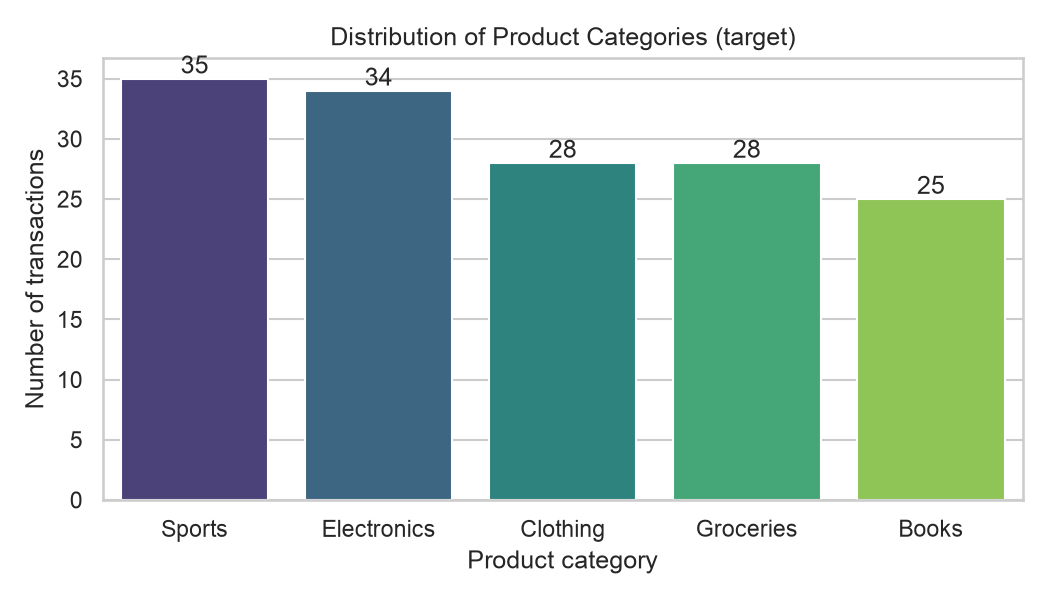

In [6]:
display(Image("plots/eda_1_target_distribution.png"))

**Interpretation:** the five categories are fairly balanced (Sports 35, Electronics 34, Clothing 28, Groceries 28, Books 25). There is no severe class imbalance, so accuracy is a meaningful metric and no resampling is required. A random guess would score about 20% and the majority-class baseline is about 23%.

### 4.3 Plot 2 - Purchase amount distribution and outliers

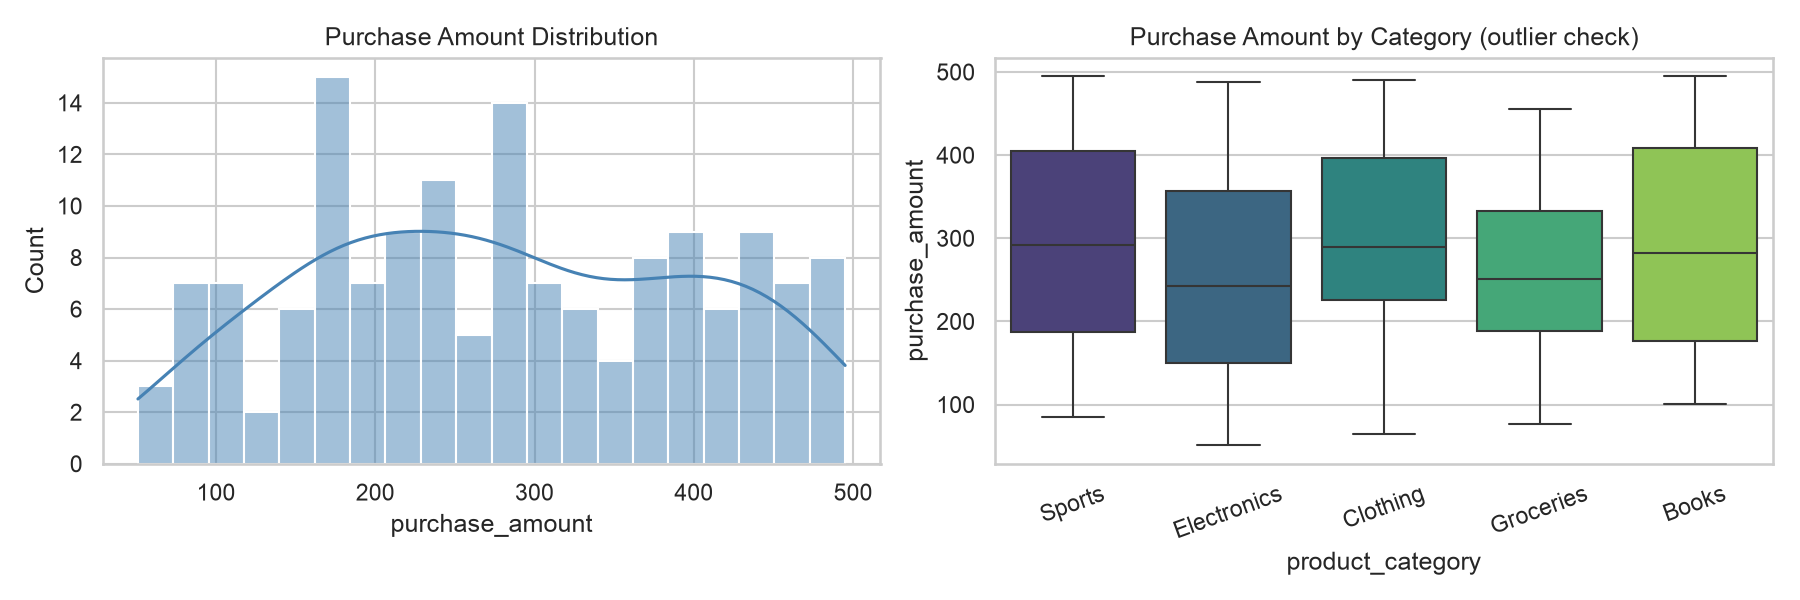

In [7]:
display(Image("plots/eda_2_purchase_amount.png"))

**Interpretation:** purchase amounts are spread almost uniformly across about 50-500 with no long tail, and the box plots show similar medians and ranges for every category. Price alone therefore does not separate the categories.

### 4.4 Plot 3 - Correlation heatmap

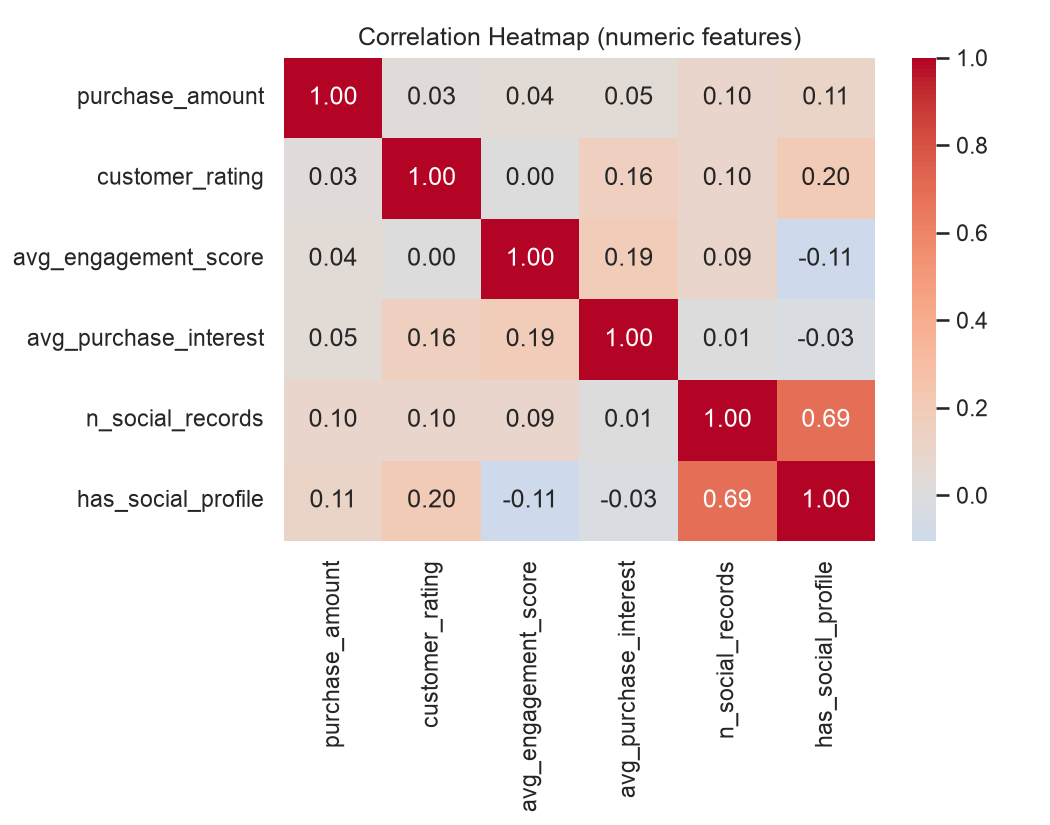

In [8]:
display(Image("plots/eda_3_correlation_heatmap.png"))

**Interpretation:** correlations between the numeric features are weak. The strongest genuine relationships are `customer_rating` with `has_social_profile` (0.20) and `avg_engagement_score` with `avg_purchase_interest` (0.19). The 0.69 between `n_social_records` and `has_social_profile` is structural: the count is 0 exactly when there is no profile. Low correlation among the features means little redundancy, so no feature needs to be dropped for multicollinearity.

### 4.5 Plot 4 - Rating and social interest by category

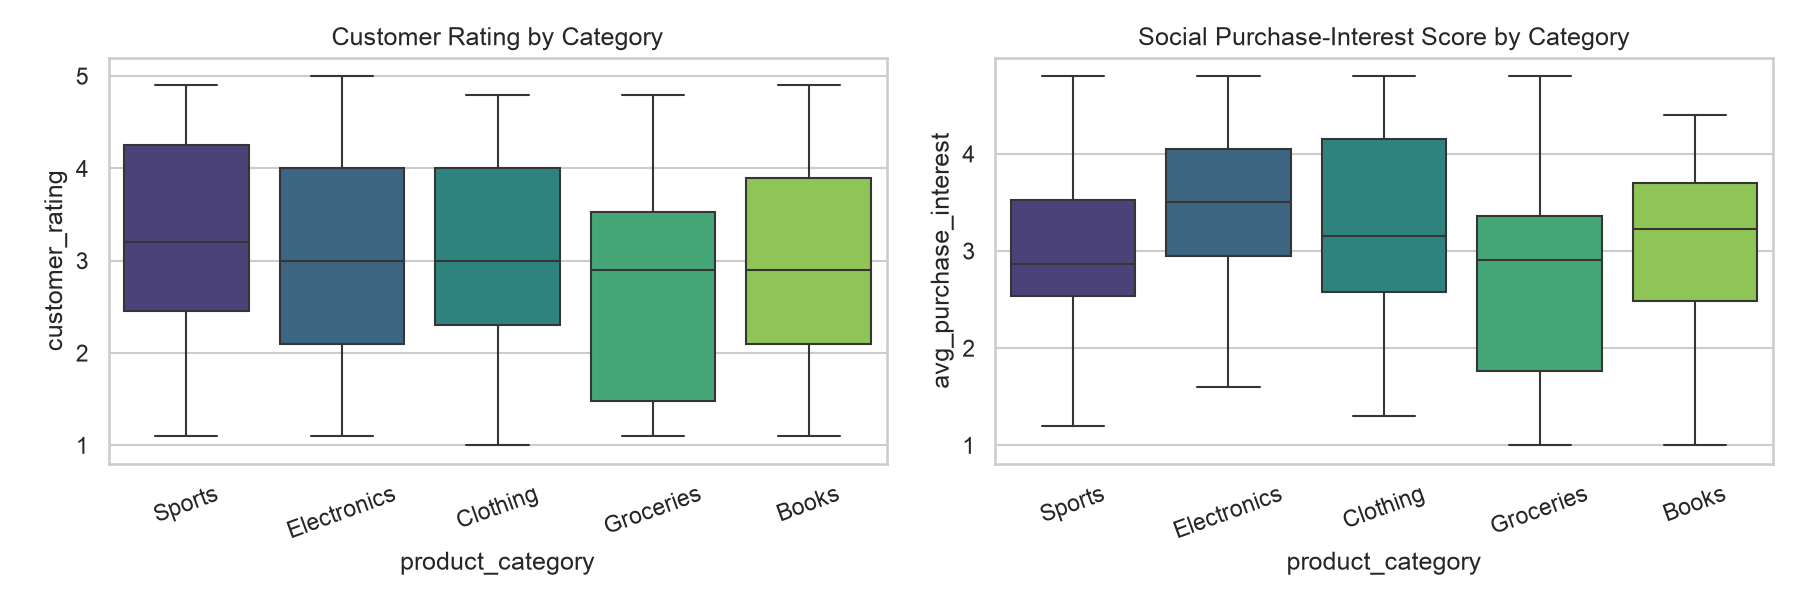

In [9]:
display(Image("plots/eda_4_rating_interest_by_category.png"))

**Interpretation:** the distributions overlap heavily across all five categories. There is no category with a clearly higher rating or social purchase-interest score.

### 4.6 Plot 5 - Platform and sentiment by category

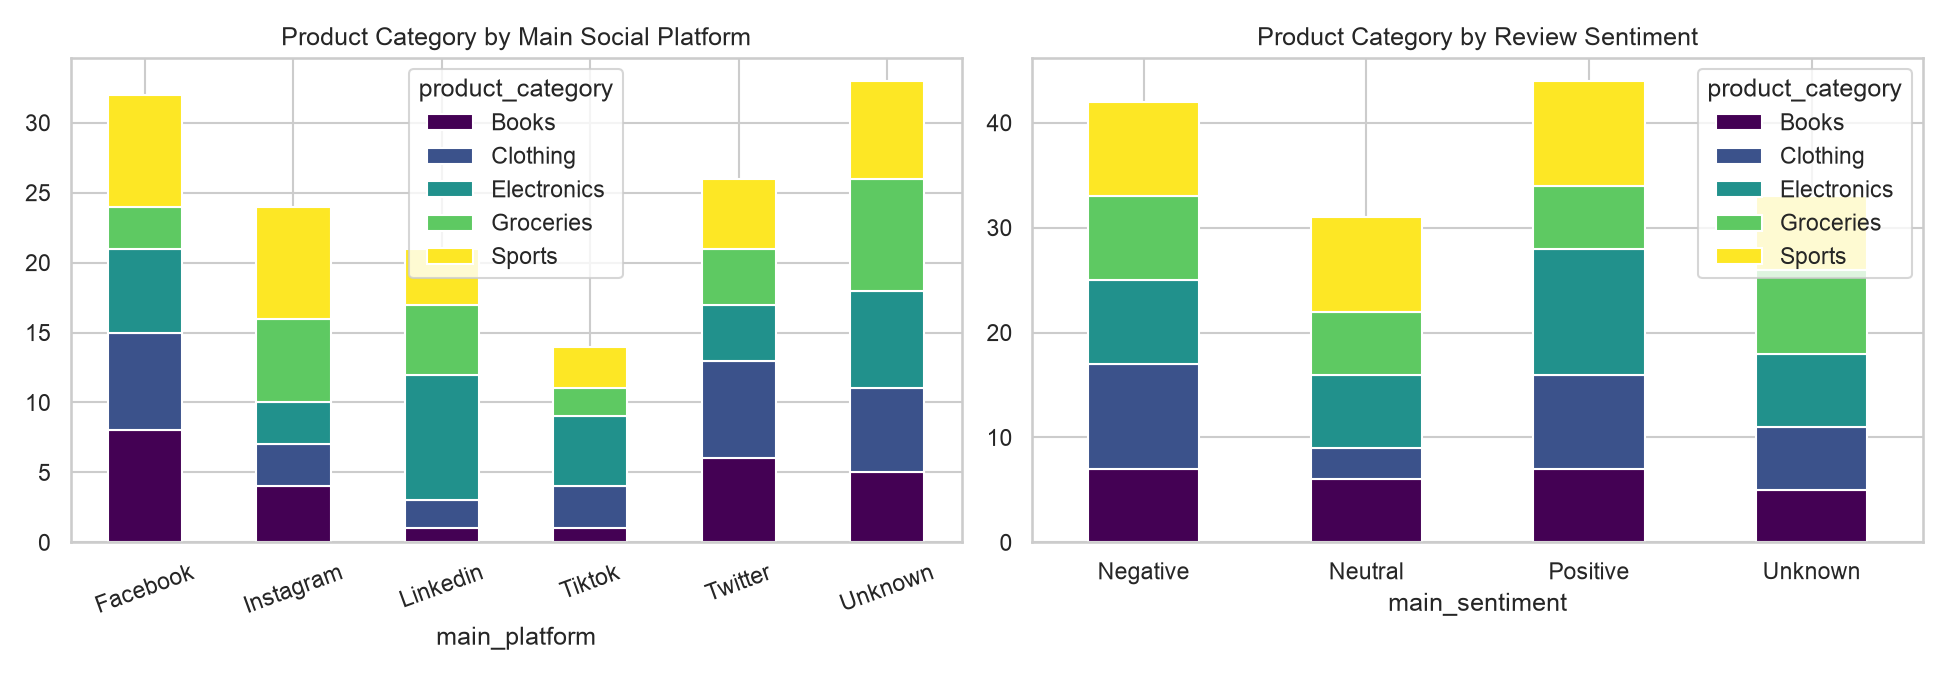

In [10]:
display(Image("plots/eda_5_platform_sentiment.png"))

**Interpretation:** each platform and sentiment value is spread across all categories rather than concentrating in one. The tests printed above confirm this: **none** of the features is significantly related to product category at the 5% level (ANOVA p-values 0.08 to 0.64 for the numeric features, chi-square p-values 0.55 and 0.97 for platform and sentiment). The closest is `avg_purchase_interest` (p = 0.076).

**EDA conclusion:** the data is clean and balanced, but the available features carry only a weak signal about which product a customer buys. We should expect modest model performance and evaluate it against baselines.

## 5. Feature engineering

Features created for the model (none uses the target column, so there is no label leakage):

| Feature | Description |
|---|---|
| `purchase_month`, `purchase_dayofweek`, `is_weekend` | Calendar features from `purchase_date` |
| `customer_n_purchases`, `customer_avg_amount`, `customer_avg_rating` | Customer-level purchase behaviour |
| `amount_vs_customer_avg` | How much this purchase deviates from the customer's usual spend |
| `engagement_x_interest` | Interaction of the two social scores |
| `amount_bucket_*` | Purchase amount in quartiles (low / mid / high / premium), one-hot encoded |
| `main_platform_*`, `main_sentiment_*` | One-hot encoded social features |
| `has_social_profile`, `rating_was_missing` | Flags that record how the row was filled |

In [11]:
final = pm.engineer_features(merged)
final.to_csv("data/merged_dataset.csv", index=False)
print("Final dataset shape:", final.shape)
display(final.head())

Final dataset shape: (150, 33)


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,rating_was_missing,avg_engagement_score,avg_purchase_interest,n_social_records,has_social_profile,purchase_month,purchase_dayofweek,is_weekend,customer_n_purchases,customer_avg_amount,customer_avg_rating,amount_vs_customer_avg,engagement_x_interest,main_platform_Facebook,main_platform_Instagram,main_platform_Linkedin,main_platform_Tiktok,main_platform_Twitter,main_platform_Unknown,main_sentiment_Negative,main_sentiment_Neutral,main_sentiment_Positive,main_sentiment_Unknown,amount_bucket_low,amount_bucket_mid,amount_bucket_high,amount_bucket_premium
0,151,1001,408,2024-01-01,Sports,2.3,0,71.666667,2.166667,3.0,1,1,0,0,1,408.0,2.300000,0.0,155.277778,0,0,0,0,1,0,0,1,0,0,0,0,0,1
1,192,1002,332,2024-01-02,Electronics,4.2,0,60.000000,4.300000,1.0,1,1,1,0,2,411.5,4.050000,-79.5,258.000000,0,1,0,0,0,0,0,0,1,0,0,0,1,0
2,114,1003,442,2024-01-03,Electronics,2.1,0,87.000000,4.800000,1.0,1,1,2,0,4,258.5,3.500000,183.5,417.600000,1,0,0,0,0,0,1,0,0,0,0,0,0,1
3,171,1004,256,2024-01-04,Clothing,2.8,0,77.000000,3.133333,0.0,0,1,3,0,3,181.0,2.266667,75.0,241.266667,0,0,0,0,0,1,0,0,0,1,0,1,0,0
4,160,1005,64,2024-01-05,Clothing,1.3,0,72.666667,2.500000,3.0,1,1,4,0,1,64.0,1.300000,0.0,181.666667,0,1,0,0,0,0,0,1,0,0,1,0,0,0


## 6. Model training and evaluation

Three models are compared on a stratified 75/25 train/test split, plus 5-fold cross-validation (more reliable than a single 38-row test set):
- **Logistic Regression** (scaled features) - simple linear baseline
- **Random Forest** - handles non-linear interactions
- **XGBoost** - gradient boosting

Metrics: **accuracy**, **weighted F1-score** and **log loss** (the loss metric for a probabilistic classifier). The model with the best weighted F1 is saved.

In [12]:
artifact, metrics = pm.train_and_evaluate(final)


--- MODEL COMPARISON ---
Logistic Regression  {'accuracy': 0.2105, 'f1_weighted': 0.2064, 'f1_macro': 0.2032, 'log_loss': 2.3767, 'cv_accuracy_5fold': np.float64(0.2133)}
Random Forest        {'accuracy': 0.2632, 'f1_weighted': 0.2595, 'f1_macro': 0.2531, 'log_loss': 1.6108, 'cv_accuracy_5fold': np.float64(0.24)}
XGBoost              {'accuracy': 0.2632, 'f1_weighted': 0.2566, 'f1_macro': 0.2509, 'log_loss': 1.8883, 'cv_accuracy_5fold': np.float64(0.2133)}

Majority-class baseline accuracy: 0.2368
Random-guess log loss (ln 5): 1.6094

Selected model: Random Forest

--- CLASSIFICATION REPORT (test set) ---
              precision    recall  f1-score   support

       Books       0.33      0.17      0.22         6
    Clothing       0.25      0.14      0.18         7
 Electronics       0.40      0.44      0.42         9
   Groceries       0.22      0.29      0.25         7
      Sports       0.17      0.22      0.19         9

    accuracy                           0.26        38
   mac

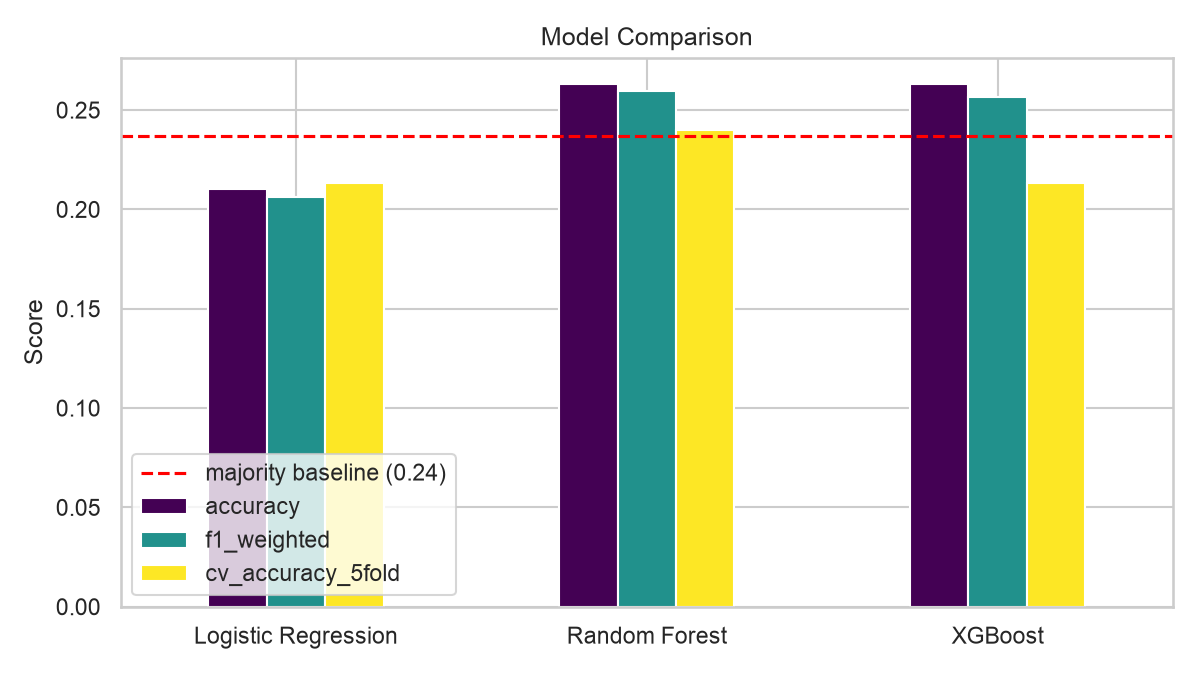

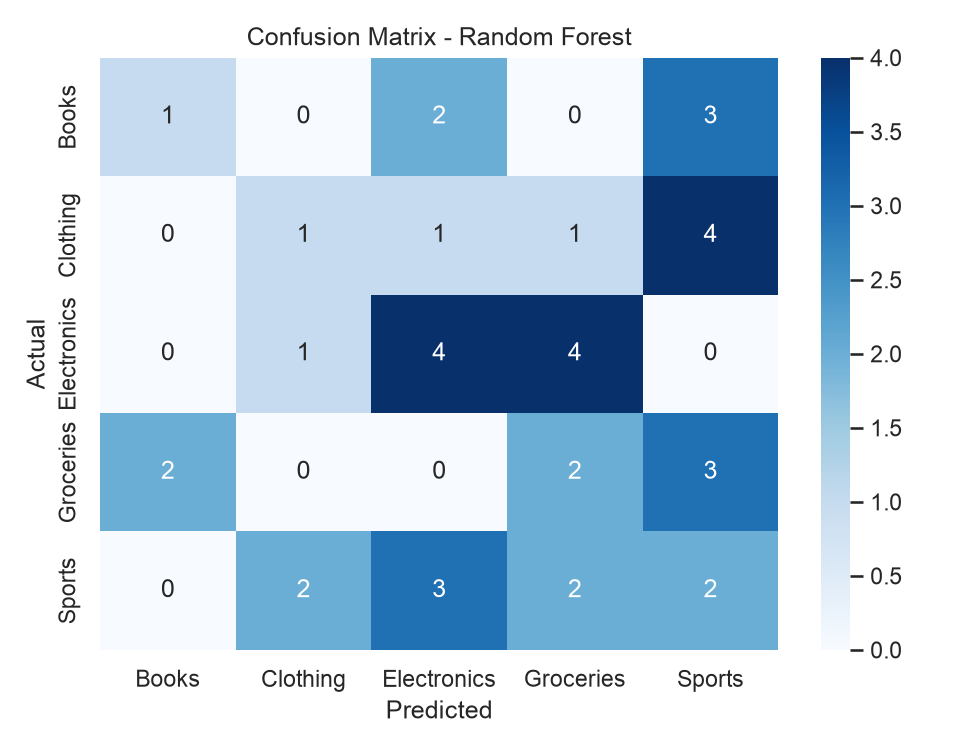

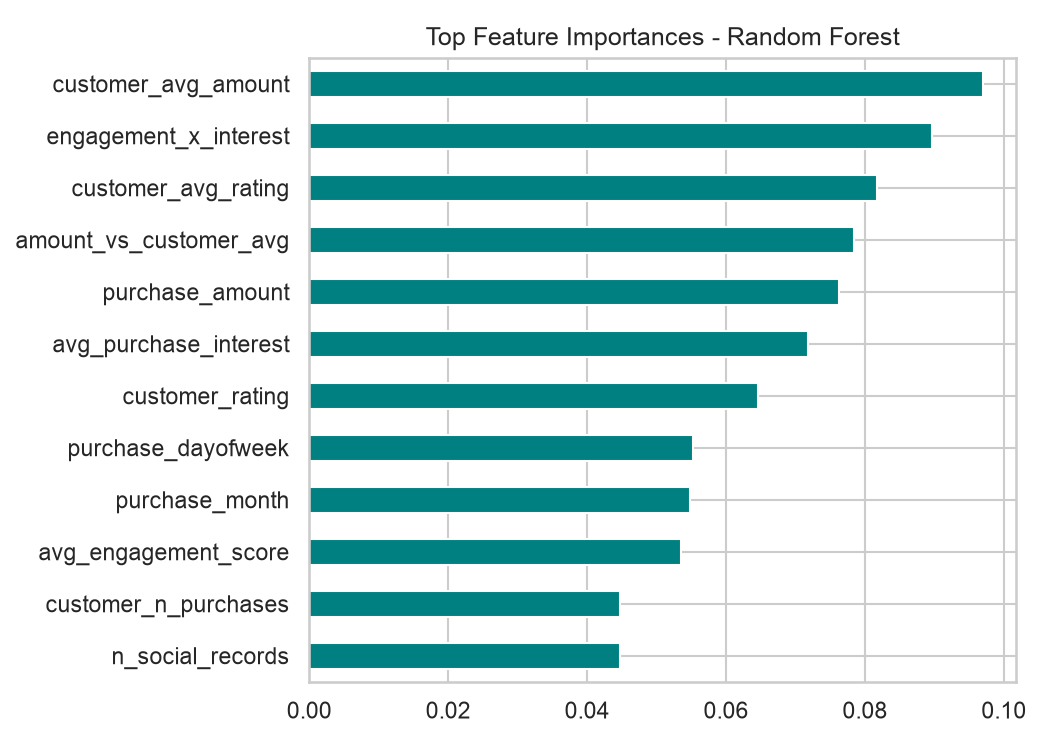

In [13]:
display(Image("plots/model_comparison.png"))
display(Image("plots/model_confusion_matrix.png"))
display(Image("plots/model_feature_importance.png"))

### Interpretation of results

| Model | Test accuracy | Weighted F1 | Log loss | 5-fold CV accuracy |
|---|---|---|---|---|
| Logistic Regression | 0.211 | 0.206 | 2.377 | 0.213 |
| **Random Forest (selected)** | **0.263** | **0.260** | **1.610** | **0.240** |
| XGBoost | 0.263 | 0.254 | 1.910 | 0.220 |
| *Majority-class baseline* | 0.237 | - | - | - |
| *Random guess (5 classes)* | 0.200 | - | 1.609 | 0.200 |

**What these numbers say:**
- The Random Forest was selected for the best weighted F1 and the lowest log loss. Its accuracy is only slightly above the majority baseline and random guessing, so the model has **little real predictive power**.
- Its log loss (1.610) is essentially equal to the loss of random guessing (ln 5 = 1.609), meaning its predicted probabilities are not better calibrated than a uniform guess. Logistic Regression and XGBoost have a *worse* loss than random because they are overconfident on a very small training set (112 rows).
- This matches the EDA: no feature is significantly associated with the product category, so any model is limited by the data, not by the algorithm. The test set has only 38 rows, so differences of a few points are within noise.
- Electronics is the category predicted best (F1 about 0.42), the others are close to chance.

**How the system uses this:** the pipeline is complete and functional (merged data -> features -> trained model -> `predict_product()`). In the full flow the product model only runs after the face check passes, and the output is shown only after the voice check passes, so the security logic does not depend on this model's accuracy.

**What would improve it with more time:** more transactions per customer, richer behavioural features (previous categories bought, browsing history), and hyperparameter tuning with a larger validation set.

## 7. Inference function used by the CLI app

In [14]:
product, confidence = pm.predict_product(151)
print(f"Predicted product for customer 151: {product} (confidence {confidence:.2%})")

Predicted product for customer 151: Sports (confidence 25.08%)
